In [89]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

from xgboost import XGBClassifier

df = pd.read_csv('../01 - DataPreparation/df_prepared.csv')

All variables are kept as XGBoost uses decision trees and is therefore strong against useless features.

In [ ]:
feature_columns = ['GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Age', 'AvgPlaytime', 'AgeRec']

X = df[feature_columns]
y = df['Rating']


In [91]:
# Encode labels for XGBoost (safe + explicit)
le = LabelEncoder()
y_enc = le.fit_transform(y)  # integers 0..K-1
class_names = le.classes_
num_classes = len(class_names)

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc,
    test_size=0.3,
    random_state=42,
    stratify=y_enc
)

In [93]:
xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=num_classes,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    eval_metric="mlogloss"
)

xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_names))


Accuracy: 0.72

Confusion Matrix:
 [[ 975   25  434]
 [  14 1446  524]
 [ 244  470 2040]]

Classification Report:
               precision    recall  f1-score   support

        High       0.79      0.68      0.73      1434
         Low       0.74      0.73      0.74      1984
      Medium       0.68      0.74      0.71      2754

    accuracy                           0.72      6172
   macro avg       0.74      0.72      0.73      6172
weighted avg       0.73      0.72      0.72      6172



Base XGBoost performs strongly with 0.72 accuracy and solid, fairly balanced class metrics (macro F1 = 0.73). Low and Medium are predicted best (recall 0.73–0.74), while High is the hardest (recall 0.68) and is most often confused with Medium.

In [94]:
param_grid = {
    "n_estimators": [300, 600],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "min_child_weight": [1, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.5],
    "reg_lambda": [1.0, 2.0],
}

base_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=num_classes,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    eval_metric="mlogloss"
)

xgb_grid = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print("Best Parameters:", xgb_grid.best_params_)
print("Best CV F1 Score:", xgb_grid.best_score_)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
Best Parameters: {'colsample_bytree': 1.0, 'gamma': 0.5, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'reg_lambda': 1.0, 'subsample': 0.8}
Best CV F1 Score: 0.7280221209112577


Tuned XGBoost favors a moderately deep model (max_depth=5) with stronger regularization (gamma=0.5, subsample=0.8) and a lower learning rate (0.05) with more trees (300), reaching a CV macro-F1 of ~0.728, essentially matching/slightly improving the strong base performance while improving stability/generalization.

In [99]:
best_xgb = xgb_grid.best_estimator_

y_pred_train = best_xgb.predict(X_train)
y_pred_test = best_xgb.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy: {test_acc:.3f}\n")

print("Confusion Matrix (Test Set):")
print(confusion_matrix(y_test, y_pred_test))

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test, target_names=class_names))

Train accuracy: 0.797
Test accuracy: 0.725

Confusion Matrix (Test Set):
[[ 986   27  421]
 [  15 1446  523]
 [ 246  465 2043]]

Classification Report (Test Set):
              precision    recall  f1-score   support

        High       0.79      0.69      0.74      1434
         Low       0.75      0.73      0.74      1984
      Medium       0.68      0.74      0.71      2754

    accuracy                           0.73      6172
   macro avg       0.74      0.72      0.73      6172
weighted avg       0.73      0.73      0.73      6172



Tuned XGBoost shows strong overall performance with 0.725 test accuracy (train 0.797, low overfitting). Class results are balanced and high (macro F1 ≈ 0.73): Low and Medium remain the most reliable, while High is slightly harder and is mainly confused with Medium.

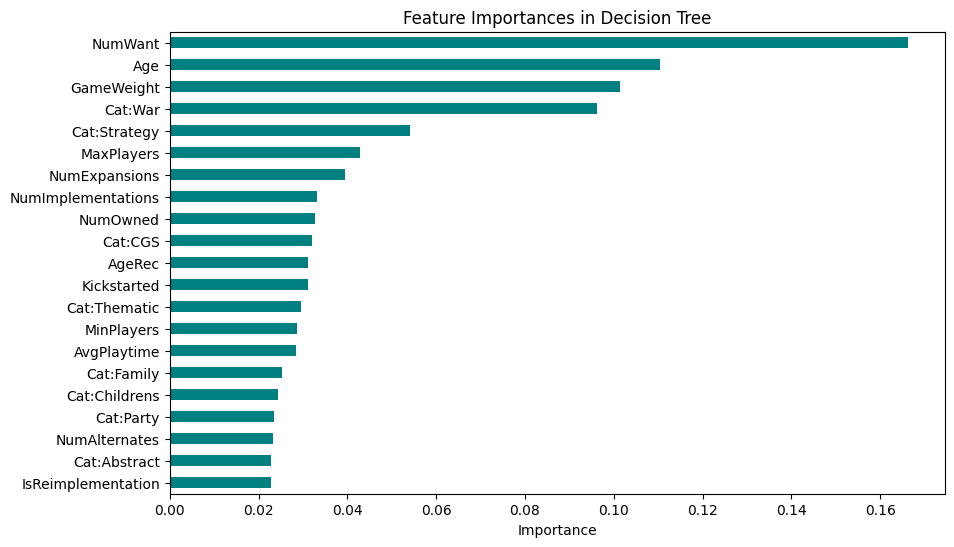

In [100]:
importances = pd.Series(best_xgb.feature_importances_, index=feature_columns).sort_values(ascending=True)

plt.figure(figsize=(10,6))
importances.plot(kind='barh', color='teal')
plt.title("Feature Importances in Decision Tree")
plt.xlabel("Importance")
plt.show()

The decision tree relies most on NumWant (by far the top feature), followed by Age and GameWeight, with War/Strategy category flags also contributing notably; the remaining features have relatively small individual impact.

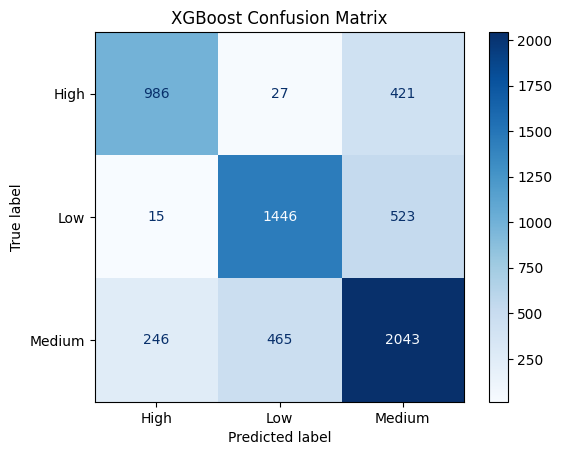

In [101]:
cm = confusion_matrix(y_test, y_pred_test, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("XGBoost Confusion Matrix")
plt.show()

XGBoost Confusion Matrix: Most predictions are correct (strong diagonal). The main mistakes are High -> Medium (421) and Low -> Medium (523), with some Medium -> Low (465); High <-> Low confusion is minimal.

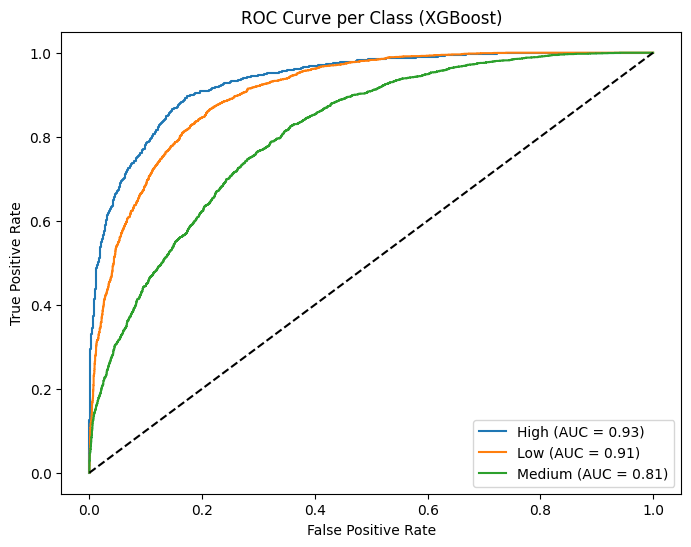

In [102]:
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
y_score = best_xgb.predict_proba(X_test)

plt.figure(figsize=(8, 6))
for i, class_label in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{class_label} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve per Class (XGBoost)")
plt.legend()
plt.show()

Class separability is strong for High (AUC = 0.93) and Low (AUC = 0.91), and still good for Medium (AUC = 0.81), though Medium is the hardest class to distinguish.